# Expérimentations préliminaires — 4. Comparaison des modèles

Lit les prédictions sauvegardées par les notebooks 01 à 03 (exécuter ceux-ci d'abord) et les
compare à une **référence naïve** : probabilité constante égale au taux de victoire locale de
l'entraînement du pli (avantage de la glace seulement).

Toutes les prédictions portent sur les mêmes matchs (10 saisons testées, 2016-17 à
2025-26, 12 282 matchs). Les résumés distinguent le **développement** (2016-17 à 2023-24)
de l'**évaluation finale** (2024-25 et 2025-26) ; les sections 5 et 6 regroupent les deux.

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from nhl_forecast.data.sources.predictions_externes import charger_compilees
from nhl_forecast.evaluation.preliminaire import (
    DEVELOPPEMENT,
    FIG_DIR,
    FINALE,
    charger_predictions,
    exporter_tableau,
    formater,
    metriques,
    reference_naive,
    resultats_par_pli,
    resume,
)
from nhl_forecast.features.equipes import charger_equipes, construire_matchs
from nhl_forecast.visualization.style import COULEURS, MARQUEURS, TRAITS, appliquer_style

SAUVER = True
appliquer_style()

In [3]:
matchs = construire_matchs(charger_equipes())
preds = pd.concat([reference_naive(matchs), charger_predictions()], ignore_index=True)
ORDRE = ["Référence (taux local)", "Régression logistique", "XGBoost", "LSTM"]
preds["modele"] = pd.Categorical(preds["modele"], ORDRE, ordered=True)
preds = preds.sort_values(["modele", "pli"])
matchs_par_modele = preds.groupby("modele", observed=True)["gameId"].apply(frozenset)
assert len(set(matchs_par_modele)) == 1, (  # mêmes matchs pour tous les modèles
    "Les modèles ne portent pas sur les mêmes matchs : "
    f"{preds.groupby('modele', observed=True)['saison'].agg(['size', 'min', 'max']).to_dict('index')}. "
    "Redémarrer le kernel (configuration chargée à l'import) ou relancer les notebooks 01 à 03."
)
preds.groupby("modele", observed=True).size()

C:\Users\tom_9\Projets\nhl-probabilistic-forecasting\src\nhl_forecast\features\equipes.py:205: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  matchs = matchs.astype({"visiteur": "int64"}).reset_index()


modele
Référence (taux local)    12282
Régression logistique     12282
XGBoost                   12282
LSTM                      12282
dtype: int64

## 1. Résumé : moyenne ± écart-type sur les saisons testées

Log loss et Brier : plus bas = meilleur. Accuracy : plus haut = meilleur.

### 1.1 Développement (plis 1 à 8, saisons 2016-17 à 2023-24)

In [4]:
tab_resume = resume(preds.assign(modele=preds["modele"].astype(str)))
tab_resume_dev = tab_resume[tab_resume["Phase"] == DEVELOPPEMENT].drop(columns="Phase")
tab_resume_finale = tab_resume[tab_resume["Phase"] == FINALE].drop(columns="Phase")
if SAUVER:
    exporter_tableau(tab_resume_dev, "exp_comparaison_resume_developpement")
    exporter_tableau(tab_resume_finale, "exp_comparaison_resume_finale")
formater(tab_resume_dev)

Modèle,Saisons,Log loss,Brier,Accuracy
Référence (taux local),8,0.6898 ± 0.0024,0.2484 ± 0.0012,0.5409 ± 0.0136
Régression logistique,8,0.6780 ± 0.0095,0.2423 ± 0.0046,0.5781 ± 0.0242
XGBoost,8,0.6749 ± 0.0083,0.2411 ± 0.0040,0.5817 ± 0.0227
LSTM,8,0.6808 ± 0.0086,0.2438 ± 0.0041,0.5683 ± 0.0147


### 1.2 Évaluation finale (plis 9 et 10, saisons 2024-25 et 2025-26)

In [5]:
formater(tab_resume_finale)

Modèle,Saisons,Log loss,Brier,Accuracy
Référence (taux local),2,0.6896 ± 0.0049,0.2482 ± 0.0025,0.5423 ± 0.0286
Régression logistique,2,0.6770 ± 0.0124,0.2421 ± 0.0059,0.5614 ± 0.0372
XGBoost,2,0.6763 ± 0.0115,0.2418 ± 0.0056,0.5675 ± 0.0275
LSTM,2,0.6820 ± 0.0084,0.2443 ± 0.0041,0.5572 ± 0.0194


## 2. Log loss par saison testée

In [6]:
par_pli = resultats_par_pli(preds.assign(modele=preds["modele"].astype(str)))
tab_ll = par_pli.pivot_table(index="Saison testée", columns="Modèle", values="Log loss")[ORDRE].reset_index()
tab_brier = par_pli.pivot_table(index="Saison testée", columns="Modèle", values="Brier")[ORDRE].reset_index()
tab_acc = par_pli.pivot_table(index="Saison testée", columns="Modèle", values="Accuracy")[ORDRE].reset_index()
if SAUVER:
    exporter_tableau(par_pli, "exp_comparaison_par_pli")
    exporter_tableau(tab_ll, "exp_comparaison_logloss_saisons")
formater(tab_ll)

Saison testée,Référence (taux local),Régression logistique,XGBoost,LSTM
2016-17,0.6866,0.6816,0.6801,0.6858
2017-18,0.6857,0.6780,0.6811,0.6860
2018-19,0.6907,0.6844,0.6830,0.6879
2019-20,0.6913,0.6902,0.6847,0.6916
2020-21,0.6912,0.6857,0.6718,0.6822
2021-22,0.6906,0.6609,0.6627,0.6729
2022-23,0.6929,0.6705,0.6686,0.6686
2023-24,0.6898,0.6729,0.6676,0.6718
2024-25,0.6861,0.6682,0.6682,0.6760
2025-26,0.6931,0.6858,0.6844,0.6880


## 3. Score de Brier par saison testée

In [7]:
formater(tab_brier)

Saison testée,Référence (taux local),Régression logistique,XGBoost,LSTM
2016-17,0.2467,0.2443,0.2436,0.2464
2017-18,0.2463,0.2423,0.2440,0.2464
2018-19,0.2488,0.2453,0.2449,0.2472
2019-20,0.2491,0.2483,0.2459,0.2490
2020-21,0.2490,0.2459,0.2396,0.2442
2021-22,0.2487,0.2343,0.2350,0.2401
2022-23,0.2499,0.2383,0.2379,0.2379
2023-24,0.2483,0.2400,0.2375,0.2395
2024-25,0.2465,0.2380,0.2378,0.2414
2025-26,0.2500,0.2463,0.2457,0.2472


## 4. Accuracy par saison testée

In [8]:
formater(tab_acc)

Saison testée,Référence (taux local),Régression logistique,XGBoost,LSTM
2016-17,0.5593,0.5675,0.5593,0.5488
2017-18,0.5633,0.5799,0.5956,0.5649
2018-19,0.5366,0.5720,0.5728,0.5531
2019-20,0.5333,0.5444,0.5434,0.5564
2020-21,0.5334,0.5553,0.5749,0.5760
2021-22,0.5366,0.6212,0.6075,0.5777
2022-23,0.5236,0.5892,0.6006,0.5907
2023-24,0.5412,0.5953,0.5991,0.5785
2024-25,0.5625,0.5877,0.5869,0.5709
2025-26,0.5221,0.5351,0.5480,0.5434


## 5. Ensemble des matchs testés

Métriques calculées sur l'ensemble des 12 282 matchs testés (plis regroupés). L'erreur de
calibration attendue (ECE, 10 classes de même effectif) complète l'analyse de calibration.

In [9]:
def ece(y, p, n_classes=10):
    classes = pd.qcut(p, n_classes, labels=False, duplicates="drop")
    d = pd.DataFrame({"y": y, "p": p, "c": classes}).groupby("c")
    return float((d.size() / len(p) * (d["y"].mean() - d["p"].mean()).abs()).sum())


tab_global = pd.DataFrame([
    {"Modèle": m, **metriques(g["y"], g["p"]), "ECE": ece(g["y"].to_numpy(), g["p"].to_numpy())}
    for m, g in preds.groupby("modele", observed=True)
])
if SAUVER:
    exporter_tableau(tab_global, "exp_comparaison_global")
formater(tab_global)

Modèle,Log loss,Brier,Accuracy,ECE
Référence (taux local),0.6898,0.2483,0.5414,0.0140
Régression logistique,0.6773,0.2420,0.5760,0.0180
XGBoost,0.6751,0.2411,0.5797,0.0162
LSTM,0.6808,0.2438,0.5660,0.0242


## 6. Diagramme de fiabilité

Matchs testés regroupés en 10 classes de même effectif selon la probabilité prédite ; pour
chaque classe, fréquence observée de victoires locales en fonction de la probabilité moyenne
prédite. Un modèle parfaitement calibré suit la diagonale. Couleurs, traits et marqueurs
distincts permettent la lecture en noir et blanc.

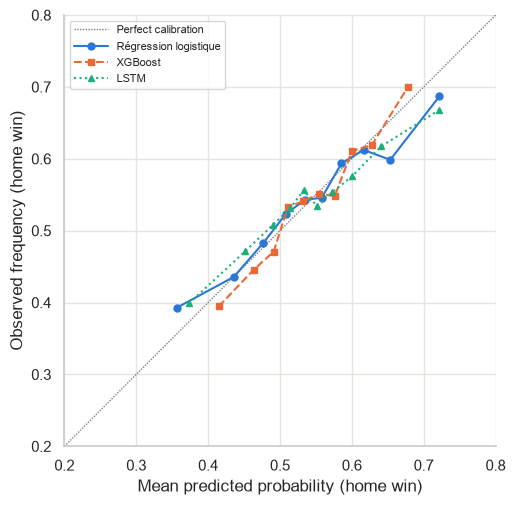

In [10]:
fig, ax = plt.subplots(figsize=(5.2, 5.2))
ax.plot([0.2, 0.8], [0.2, 0.8], color="0.5", linestyle=(0, (1, 1)), marker="", linewidth=1,
        label="Perfect calibration")
for i, m in enumerate(ORDRE[1:]):
    g = preds[preds["modele"] == m]
    c = pd.qcut(g["p"], 10, labels=False, duplicates="drop")
    pts = g.groupby(c)[["p", "y"]].mean()
    ax.plot(pts["p"], pts["y"], color=COULEURS[i], linestyle=TRAITS[i], marker=MARQUEURS[i],
            markersize=5, label=m)
ax.set(xlabel="Mean predicted probability (home win)", ylabel="Observed frequency (home win)",
       xlim=(0.2, 0.8), ylim=(0.2, 0.8), aspect="equal")
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
if SAUVER:
    fig.savefig(FIG_DIR / "exp_fiabilite.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Sources externes

Prédictions publiées par des sites de prédiction (méthodes non divulguées), notées à la main
au fil du temps dans `data/external/` (un `README.md` par site). Seule la probabilité de
victoire locale est retenue ; les valeurs de 0 % / 100 % (prédictions non notées) sont exclues.
Chaque prédiction est appariée au match officiel (gameId) par
`scripts/compiler_predictions_externes.py`, qui produit un CSV par site
(`data/external/<site>/predictions_<site>.csv`, prédictions valides seulement).

**Attention :** les sources couvrent des saisons et des nombres de matchs très différents
(de 56 matchs à deux saisons complètes). Les métriques de deux sources ne sont comparables
que sur les **mêmes matchs** (section 7.3).

### 7.1 Couverture

In [11]:
ext = charger_compilees()
NB_MATCHS_SAISON = {"2017-18": 1271, "2018-19": 1271, "2021-22": 1312, "2024-25": 1312,
                    "2025-26": 1312}
lignes = []
for (src, saison), g in ext.groupby(["source", "Saison"], sort=False):
    lignes.append({"Source": src, "Saison": saison, "Début": g["Date"].min(), "Fin": g["Date"].max(),
                   "Matchs": len(g)})
tab_ext_couv = pd.DataFrame(lignes)
if SAUVER:
    exporter_tableau(tab_ext_couv, "exp_externes_couverture", 1)
formater(tab_ext_couv, 1)

Source,Saison,Début,Fin,Matchs
Forecheck,2017-18,2017-10-04,2018-04-08,1271
dRatings,2018-19,2018-10-03,2018-10-11,56
The Athletic,2018-19,2019-01-23,2019-03-08,148
Sports Club Stats,2018-19,2019-01-06,2019-02-21,127
MoneyPuck,2021-22,2022-01-03,2022-03-02,226
MySports.ai,2024-25,2024-10-05,2025-04-17,1309
MySports.ai,2025-26,2025-10-07,2026-04-16,1312


### 7.2 Performance de chaque source sur ses propres matchs

Chaque source est évaluée sur l'ensemble de ses matchs. Les sources portant sur des matchs
différents, ce tableau ne permet **pas** de les classer entre elles.

In [12]:
tab_ext_perf = pd.DataFrame([
    {"Source": src, "Saisons": ", ".join(sorted(g["Saison"].unique())), "Matchs": len(g),
     **metriques(g["Victoire locale"], g["Prob. victoire locale"])}
    for src, g in ext.groupby("source", sort=False)
])
if SAUVER:
    exporter_tableau(tab_ext_perf, "exp_externes_performance")
formater(tab_ext_perf)

Source,Saisons,Matchs,Log loss,Brier,Accuracy
Forecheck,2017-18,1271,0.6784,0.2422,0.5964
dRatings,2018-19,56,0.6768,0.2409,0.5893
The Athletic,2018-19,148,0.6400,0.2243,0.6351
Sports Club Stats,2018-19,127,0.6964,0.2515,0.5512
MoneyPuck,2021-22,226,0.6542,0.2309,0.6150
MySports.ai,"2024-25, 2025-26",2621,0.6810,0.2440,0.5555


Toutes les sources portent sur des saisons testées par nos modèles (2017-18 à 2025-26) :
elles peuvent toutes être comparées directement (section 7.3). Les échantillons de moins de
~300 matchs (dRatings, The Athletic, Sports Club Stats, MoneyPuck) ont une incertitude
importante : à titre indicatif, l'écart-type de la log loss moyenne sur 150 matchs est
d'environ 0,01 à 0,02, soit l'ordre de grandeur des écarts entre modèles.

### 7.3 Comparaison directe avec nos modèles (mêmes matchs)

Pour chaque source (Forecheck en 2017-18 ; dRatings, The Athletic et Sports Club Stats en
2018-19 ; MoneyPuck en 2021-22 ; MySports.ai en 2024-25 et 2025-26), nos modèles et la
référence naïve du pli sont évalués exactement sur les matchs prédits par la source.

In [13]:
nos = preds.assign(modele=preds["modele"].astype(str))[["modele", "gameId", "saison", "y", "p"]]
ext_nos = ext[ext["Saison"].isin(set(nos["saison"]))]
lignes = []
for (src, saison), g in ext_nos.groupby(["source", "Saison"], sort=False):
    communs = nos[nos["gameId"].isin(g["gameId"])]
    base = {"Source": src, "Saison": saison, "Matchs": int(g["gameId"].isin(communs["gameId"]).sum())}
    lignes.append({**base, "Modèle": src, **metriques(g["Victoire locale"], g["Prob. victoire locale"])})
    for m in ORDRE:
        c = communs[communs["modele"] == m]
        lignes.append({**base, "Modèle": m, **metriques(c["y"], c["p"])})
tab_ext_dir = pd.DataFrame(lignes)
if SAUVER:
    exporter_tableau(tab_ext_dir, "exp_externes_comparaison")
formater(tab_ext_dir)

Source,Saison,Matchs,Modèle,Log loss,Brier,Accuracy
Forecheck,2017-18,1271,Forecheck,0.6784,0.2422,0.5964
Forecheck,2017-18,1271,Référence (taux local),0.6857,0.2463,0.5633
Forecheck,2017-18,1271,Régression logistique,0.6780,0.2423,0.5799
Forecheck,2017-18,1271,XGBoost,0.6811,0.2440,0.5956
Forecheck,2017-18,1271,LSTM,0.6860,0.2464,0.5649
dRatings,2018-19,56,dRatings,0.6768,0.2409,0.5893
dRatings,2018-19,56,Référence (taux local),0.6943,0.2506,0.5179
dRatings,2018-19,56,Régression logistique,0.7194,0.2586,0.4464
dRatings,2018-19,56,XGBoost,0.7051,0.2557,0.5536
dRatings,2018-19,56,LSTM,0.6981,0.2523,0.5179


Même comparaison, matchs de chaque source regroupés (MySports.ai : 2024-25 et 2025-26
ensemble), log loss seulement :

In [14]:
lignes = []
for src, g in ext_nos.groupby("source", sort=False):
    communs = nos[nos["gameId"].isin(g["gameId"])]
    ligne = {"Source": src, "Saisons": ", ".join(sorted(g["Saison"].unique())), "Matchs": len(g),
             "Source externe": metriques(g["Victoire locale"], g["Prob. victoire locale"])["Log loss"]}
    for m in ORDRE:
        c = communs[communs["modele"] == m]
        ligne[m] = metriques(c["y"], c["p"])["Log loss"]
    lignes.append(ligne)
tab_ext_ll = pd.DataFrame(lignes)
if SAUVER:
    exporter_tableau(tab_ext_ll, "exp_externes_logloss")
formater(tab_ext_ll)

Source,Saisons,Matchs,Source externe,Référence (taux local),Régression logistique,XGBoost,LSTM
Forecheck,2017-18,1271,0.6784,0.6857,0.6780,0.6811,0.6860
dRatings,2018-19,56,0.6768,0.6943,0.7194,0.7051,0.6981
The Athletic,2018-19,148,0.6400,0.6912,0.6583,0.6651,0.6751
Sports Club Stats,2018-19,127,0.6964,0.6939,0.6939,0.6920,0.6936
MoneyPuck,2021-22,226,0.6542,0.6924,0.6573,0.6586,0.6950
MySports.ai,"2024-25, 2025-26",2621,0.6810,0.6895,0.6769,0.6762,0.6817


### 7.4 Stabilité temporelle : MySports.ai par quart de saison

Chaque saison de MySports.ai (2024-25 et 2025-26) est découpée en 4 portions chronologiques
de même effectif (Q1 = début de saison), soit 8 portions d'environ 328 matchs. MySports.ai,
nos modèles et la référence naïve sont évalués sur les mêmes matchs de chaque portion.
L'objectif est de montrer que la performance varie fortement d'une portion à l'autre, pour
une source externe comme pour nos modèles.

In [20]:
SOURCE_MS, N_PORTIONS = "MySports.ai", 4
ms = (ext[ext["source"] == SOURCE_MS]
      .merge(nos.pivot_table(index="gameId", columns="modele", values="p", observed=True)[ORDRE],
             on="gameId", how="inner")
      .sort_values(["Date", "gameId"]))
# 4 portions chronologiques de même effectif par saison (Q1 = début de saison)
ms["Portion"] = ms.groupby("Saison")["Date"].transform(
    lambda d: pd.qcut(range(len(d)), N_PORTIONS, labels=[f"Q{k}" for k in range(1, N_PORTIONS + 1)]))
portions_ms = ms.groupby(["Saison", "Portion"], sort=True, observed=True)
tab_ms_portions = pd.DataFrame([
    {"Saison": saison, "Début": g["Date"].min(), "Fin": g["Date"].max(), "Matchs": len(g),
     **metriques(g["Victoire locale"], g["Prob. victoire locale"])}
    for (saison, _), g in portions_ms
])
if SAUVER:
    exporter_tableau(tab_ms_portions, "exp_mysports_portions")
formater(tab_ms_portions)

Saison,Début,Fin,Matchs,Log loss,Brier,Accuracy
2024-25,2024-10-05,2024-11-23,328,0.6599,0.2338,0.6128
2024-25,2024-11-23,2025-01-09,327,0.6818,0.2444,0.5596
2024-25,2025-01-09,2025-03-05,327,0.6809,0.2440,0.5657
2024-25,2025-03-05,2025-04-17,327,0.6755,0.2415,0.5780
2025-26,2025-10-07,2025-11-20,328,0.6909,0.2489,0.5030
2025-26,2025-11-20,2026-01-03,328,0.6907,0.2488,0.5122
2025-26,2026-01-04,2026-03-06,328,0.6872,0.2470,0.5488
2025-26,2026-03-06,2026-04-16,328,0.6810,0.2440,0.5640


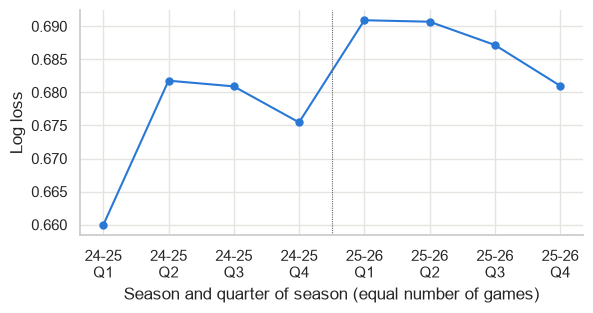

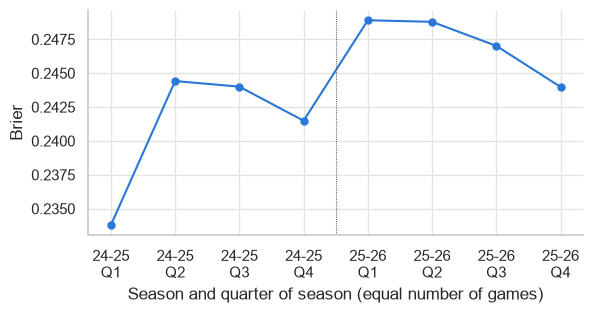

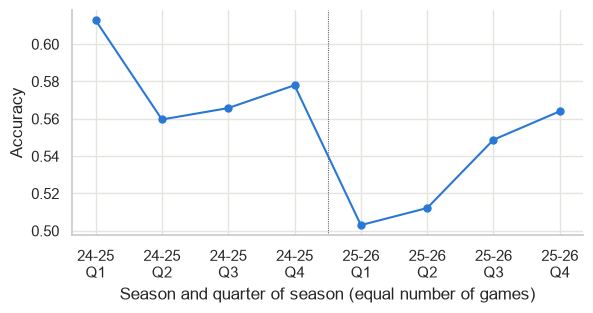

In [21]:
# Une figure par métrique (lues séparément) ; trait pointillé vertical = changement de saison
etiquettes = [f"{s[2:]}\n{p}" for s, p in portions_ms.groups]
x = range(len(etiquettes))
for metrique, nom in [("Log loss", "logloss"), ("Brier", "brier"), ("Accuracy", "accuracy")]:
    fig, ax = plt.subplots(figsize=(6, 3.2))
    ax.plot(x, tab_ms_portions[metrique], color=COULEURS[0], linestyle=TRAITS[0],
            marker=MARQUEURS[0], markersize=5)
    ax.axvline(N_PORTIONS - 0.5, color="0.4", linewidth=0.8, linestyle=(0, (1, 1)), marker="")
    ax.set_xticks(list(x), etiquettes)
    ax.set(xlabel="Season and quarter of season (equal number of games)", ylabel=metrique)
    fig.tight_layout()
    if SAUVER:
        fig.savefig(FIG_DIR / f"exp_mysports_portions_{nom}.png", dpi=300, bbox_inches="tight")
    plt.show()

## 8. Constats préliminaires

Les choix de modélisation doivent reposer sur la phase de **développement** (8 saisons,
2016-17 à 2023-24). L'évaluation finale (2024-25 et 2025-26) n'est rapportée qu'à titre de
confirmation.

**Nos modèles** (toutes les statistiques d'équipes des cinq sources, 1 060 variables ; ACP
selon le critère de Kaiser pour les trois modèles) :

- **Les trois modèles battent la référence naïve** : en développement, log loss moyenne de
  0,6749 (XGBoost), 0,6780 (régression logistique) et 0,6808 (LSTM), contre 0,6898. La
  régression logistique et XGBoost font mieux que la référence dans **les 8 saisons**, le LSTM
  dans 6 sur 8. Le signal exploitable avec les seules statistiques d'équipes est réel, mais
  modeste.
- **XGBoost obtient les meilleurs scores**, devant la régression logistique de peu : log loss
  0,6749 ± 0,0083, Brier 0,2411, accuracy 58,2 %. Il fait mieux que la régression logistique
  dans 6 saisons sur 8 (écart moyen 0,003) et que le LSTM dans 7 sur 8 (une égalité ; écart
  moyen 0,006). Les arbres retenus sont peu profonds (profondeur 2 dans 6 plis sur 10, au plus
  4) et peu nombreux (66 à 411) : les relations utiles semblent surtout simples une fois les
  variables agrégées. Le gain est très dispersé entre les composantes (CP1 ≈ 2,5 % du gain
  total, toutes les autres < 1,1 %).
- **La régression logistique ne surapprend plus.** Avec 8 100 à 16 400 matchs d'entraînement
  (contre 868 à 6 100 dans l'ancien protocole), ses 152 à 159 coefficients sont estimés de
  façon stable, sans régularisation. Elle est presque à égalité avec XGBoost.
- **Le LSTM reste dernier** (0,6808 ± 0,0086) et le moins bien calibré (ECE 0,024, contre
  0,016 à 0,018 pour les autres modèles et 0,014 pour la référence). L'arrêt précoce retient
  2 à 10 époques ; l'ACP résume les 529 statistiques d'un match en 89 à 91 composantes
  (≈ 88 % de la variance). Apprendre la forme des équipes à partir des séquences brutes reste
  plus difficile que d'utiliser des moyennes pré-calculées.
- **Plus d'historique d'entraînement améliore tous les modèles.** Sur les mêmes saisons
  testées (2021-22 à 2025-26), la log loss moyenne passe de 0,7035 à 0,6717 pour la régression
  logistique, de 0,6740 à 0,6703 pour XGBoost et de 0,6880 à 0,6755 pour le LSTM, entre
  l'ancien protocole (entraînement à partir de 2020-21) et le nouveau (à partir de 2009-10).
  Le gain est surtout marqué pour les modèles qui ont le plus de paramètres à estimer.
- **Les saisons récentes sont plus prévisibles.** En développement, XGBoost obtient 0,6801 en
  moyenne sur 2016-17 à 2020-21 et 0,6663 sur 2021-22 à 2023-24, alors que la référence reste
  stable (≈ 0,690). Plus de données d'entraînement et une ligue plus inégale peuvent toutes
  deux y contribuer ; ces expériences ne permettent pas de les distinguer.
- **L'évaluation finale confirme le classement** : log loss 0,6763 (XGBoost), 0,6770
  (régression logistique), 0,6820 (LSTM) et 0,6896 (référence) sur 2024-25 et 2025-26. Avec
  deux saisons seulement, XGBoost et la régression logistique y sont indiscernables.
- **Les écarts entre modèles (0,003 à 0,006) restent du même ordre que la variabilité entre
  saisons** (écart-type ≈ 0,008 à 0,010) : même si XGBoost est meilleur dans la plupart des
  saisons, un test apparié (bootstrap ou Diebold-Mariano) reste nécessaire avant de conclure.
- **L'accuracy (54,1 % pour la référence, 56,8 à 58,2 % pour nos modèles en développement)
  distingue peu les modèles** ; la log loss et le score de Brier sont plus informatifs pour
  juger des probabilités.

**Sources externes** (section 7, mêmes matchs) :

- Sur les deux grands échantillons, nos meilleurs modèles font **au moins aussi bien** que les
  sources publiées : Forecheck (1 271 matchs, 2017-18) obtient 0,678, comme la régression
  logistique (0,678), XGBoost faisant 0,681 ; MySports.ai (2 621 matchs, 2024-25 et 2025-26)
  obtient 0,681, contre 0,676 pour XGBoost et 0,677 pour la régression logistique.
- MoneyPuck (226 matchs, 2021-22 ; 0,654) et The Athletic (148 matchs, 2018-19 ; 0,640) font
  un peu mieux que nos modèles (0,657 à 0,665 pour la régression logistique et XGBoost) ;
  Sports Club Stats (127 matchs ; 0,696) fait moins bien que la référence naïve. Ces
  échantillons, comme celui de dRatings (56 matchs), sont trop petits pour conclure.
- Les sites ne publient pas leur méthode ni toujours le moment de la prédiction (avant ou
  après l'annonce des gardiens) : ces comparaisons restent indicatives. Les matchs de
  MySports.ai appartiennent à l'évaluation finale.

Pistes : statistiques de joueurs et de gardiens (gardien partant), sélection ou réduction des
variables (à réévaluer avec le nouveau protocole), système Elo initialisé sur 2005-06 à
2008-09, utilisation de la saison précédente en début de saison, réglage plus poussé des
hyperparamètres, recalibration et tests appariés entre modèles.